# Urban Atmospheric Pollution Analysis & Modeling Pipeline

## Problem Statement
The objective of this comprehensive study is to construct, benchmark, and compare all foundational supervised and unsupervised machine learning algorithms on the urban atmospheric air quality dataset.

### Algorithmic Scope:
1. **Linear Regression**: Baseline transfer coefficients from gaseous precursors to particulate/benzene load.
2. **Polynomial Regression (Degree 2)**: Non-linear secondary transformations and temperature-humidity interactions.
3. **Logistic Regression (With vs. Without PCA)**: Log-odds feature impact vs. 3-component orthogonal compression to tackle multi-collinearity.
4. **K-Nearest Neighbors (Regression & Classification)**: Distance-weighted state vectors and neighborhood sensitivity ($K \in [1, 25]$).
5. **K-Means Clustering**: Unsupervised atmospheric regime discovery via the Elbow Method (WCSS) and Silhouette validation.
6. **Support Vector Machines (SVR & SVC)**: $\epsilon$-insensitive margin regression and maximum-margin hyperplane classification.
7. **Naive Bayes (GaussianNB)**: Continuous probabilistic density modeling and feature independence diagnostics.
8. **Decision Trees (Regressor & Classifier)**: Piecewise-constant partitioning, statutory rule extraction, and Gini importance ranking.
9. **Unified Leaderboard & Comparative Analysis**: Complete evaluation across $R^2$, MSE, RMSE, MAE, MAPE, Residual Variance, Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

In [1]:
def configure_environment():
    import warnings
    warnings.filterwarnings('ignore')
    
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    
    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
    plt.rcParams['figure.dpi'] = 100
    np.random.seed(42)
    
    print("Environment successfully initialized with seed 42.")
    return np, pd, plt, sns

np, pd, plt, sns = configure_environment()

Environment successfully initialized with seed 42.


## 1. Data Extraction and Ingestion
Ingest the semicolon-delimited dataset, parse comma-decimal notations, and flag sentinel error readings (`-200`) as true missing entries (`NaN`).

In [ ]:
def load_and_extract_air_quality(zip_path: str = 'air+quality.zip', csv_filename: str = 'AirQualityUCI.csv'):
    import os
    import zipfile
    
    target_csv = csv_filename
    if not os.path.exists(target_csv):
        if os.path.exists(zip_path):
            with zipfile.ZipFile(zip_path, 'r') as zf:
                zf.extractall('air_quality_data')
            target_csv = os.path.join('air_quality_data', csv_filename)
        elif os.path.exists(os.path.join('air_quality_extracted', csv_filename)):
            target_csv = os.path.join('air_quality_extracted', csv_filename)
            
    df = pd.read_csv(target_csv, sep=';', decimal=',', na_values=-200)
    
    df = df.dropna(how='all', axis=1).dropna(how='all', axis=0)
    print(f"Data Ingested! Raw Records: {df.shape[0]:,} | Raw Columns: {df.shape[1]}")
    display(df.head(3))
    return df

df_raw = load_and_extract_air_quality()

Data Ingested! Raw Records: 9,357 | Raw Columns: 15


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502


## 2. Missing Data Sanitation & Temporal Feature Alignment
In the UCI dataset, `NMHC(GT)` contains over 90% missing values due to sensor deprecation and is pruned. For the remaining sensor telemetry, missing values are linearly interpolated across the time series to preserve temporal continuity. Column names are standardized into clean physical descriptors.

In [ ]:
def clean_and_impute_telemetry(df: pd.DataFrame):
    
    df_clean = df.drop(columns=['Date', 'Time', 'NMHC(GT)'], errors='ignore').copy()
    
    df_clean = df_clean.interpolate(method='linear').bfill().ffill()
    
    col_mapping = {
        'CO(GT)': 'CO_True',
        'PT08.S1(CO)': 'Sensor_CO',
        'C6H6(GT)': 'Benzene_Target',
        'PT08.S2(NMHC)': 'Sensor_NMHC',
        'NOx(GT)': 'NOx_True',
        'PT08.S3(NOx)': 'Sensor_NOx',
        'NO2(GT)': 'NO2_True',
        'PT08.S4(NO2)': 'Sensor_NO2',
        'PT08.S5(O3)': 'Sensor_O3',
        'T': 'Temperature',
        'RH': 'Relative_Humidity',
        'AH': 'Absolute_Humidity'
    }
    df_clean = df_clean.rename(columns=col_mapping)
    
    print(f"Sanitation Complete: Cleaned Dimensions = {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns")
    print(f"Remaining Missing Values: {df_clean.isna().sum().sum()}")
    return df_clean

df_clean = clean_and_impute_telemetry(df_raw)

Sanitation Complete: Cleaned Dimensions = 9,357 rows, 12 columns
Remaining Missing Values: 0


## 3. Target Formulation & Statistical Summaries
Establish the dual analytical targets:
1. **$y_{\text{reg}}$ (`Benzene_Target`)**: Continuous ambient benzene concentration ($\mu\text{g/m}^3$).
2. **$y_{\text{clf}}$ (`Air_Quality_Category`)**: Binary indicator where values exceeding $10\,\mu\text{g/m}^3$ represent severe/hazardous atmospheric pollution ($1$) and lower concentrations are acceptable ($0$).

In [ ]:
def formulate_targets_and_summarize(df: pd.DataFrame):
    df['Air_Quality_Category'] = (df['Benzene_Target'] > 10.0).astype(int)
    
    reg_stats = df['Benzene_Target'].describe()
    clf_dist = df['Air_Quality_Category'].value_counts(normalize=True) * 100
    
    print("=== Continuous Regression Target Profile (Benzene ug/m3) ===")
    display(pd.DataFrame(reg_stats).T.round(2))
    
    print("\n=== Binary Classification Category Distribution ===")
    display(pd.DataFrame({'Count': df['Air_Quality_Category'].value_counts(), 'Percentage (%)': clf_dist.round(2)}))
    return df

df_clean = formulate_targets_and_summarize(df_clean)

=== Continuous Regression Target Profile (Benzene ug/m3) ===


,count,mean,std,min,25%,50%,75%,max
Benzene_Target,9357.0,10.18,7.5,0.1,4.5,8.3,14.1,63.7



=== Binary Classification Category Distribution ===


,Count,Percentage (%)
Air_Quality_Category,,
0,5562,59.44
1,3795,40.56


## 4. Exploratory Data Analysis & Pre-Modeling Correlation Heatmap
Compute and plot the **Pearson Correlation Matrix** across all continuous gaseous, sensory, and meteorological variables to examine multi-collinearity and secondary atmospheric dependencies.

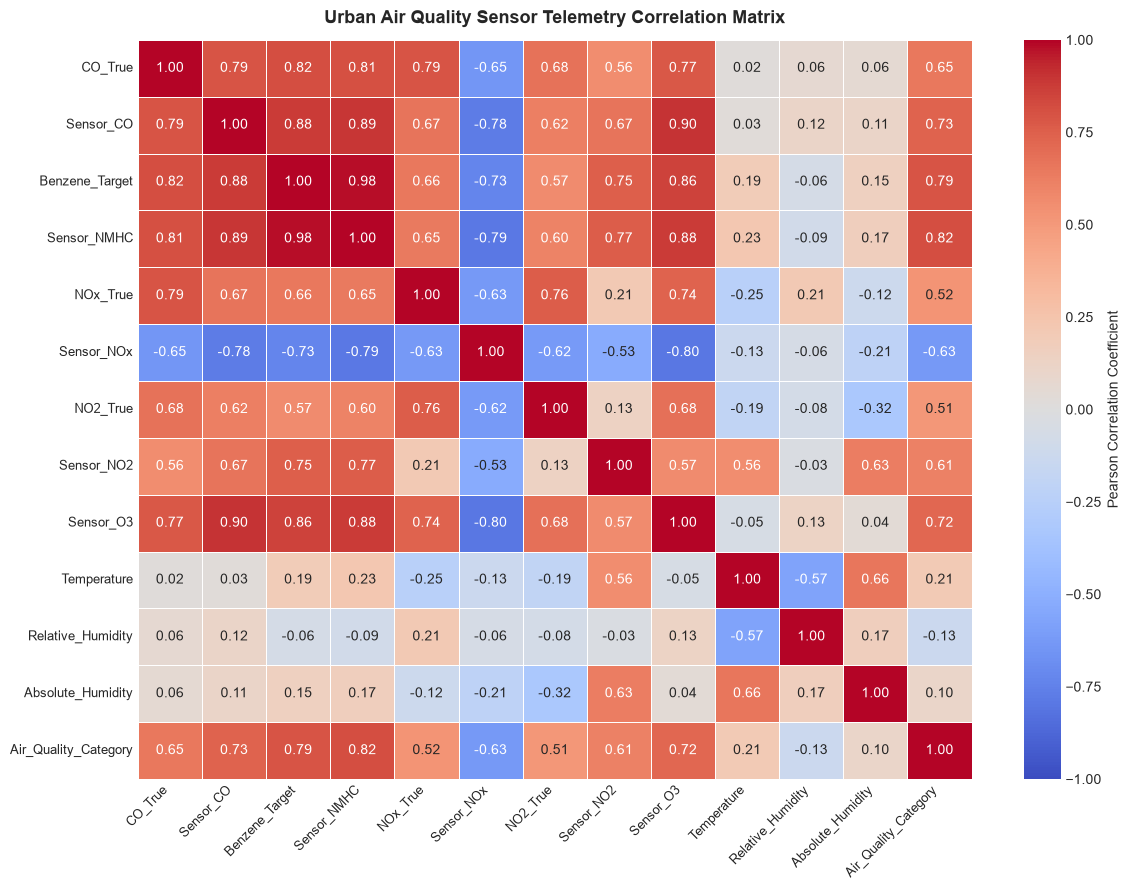

In [5]:
def plot_correlation_heatmap(df: pd.DataFrame):
    corr = df.corr()
    
    plt.figure(figsize=(12, 9))
    sns.heatmap(
        corr,
        annot=True,
        fmt='.2f',
        cmap='coolwarm',
        vmin=-1,
        vmax=1,
        linewidths=0.5,
        cbar_kws={'label': 'Pearson Correlation Coefficient'}
    )
    plt.title('Urban Air Quality Sensor Telemetry Correlation Matrix', fontsize=13, fontweight='bold', pad=12)
    plt.xticks(rotation=45, ha='right', fontsize=9.5)
    plt.yticks(fontsize=9.5)
    plt.tight_layout()
    plt.show()
    return corr

corr_matrix = plot_correlation_heatmap(df_clean)

## 5. Target Distributions & Meteorological Bivariate Plots
Visualize the continuous distribution of `Benzene_Target`, class balance for `Air_Quality_Category`, and bivariate scatter plots capturing photochemical variations across Temperature and Relative Humidity.

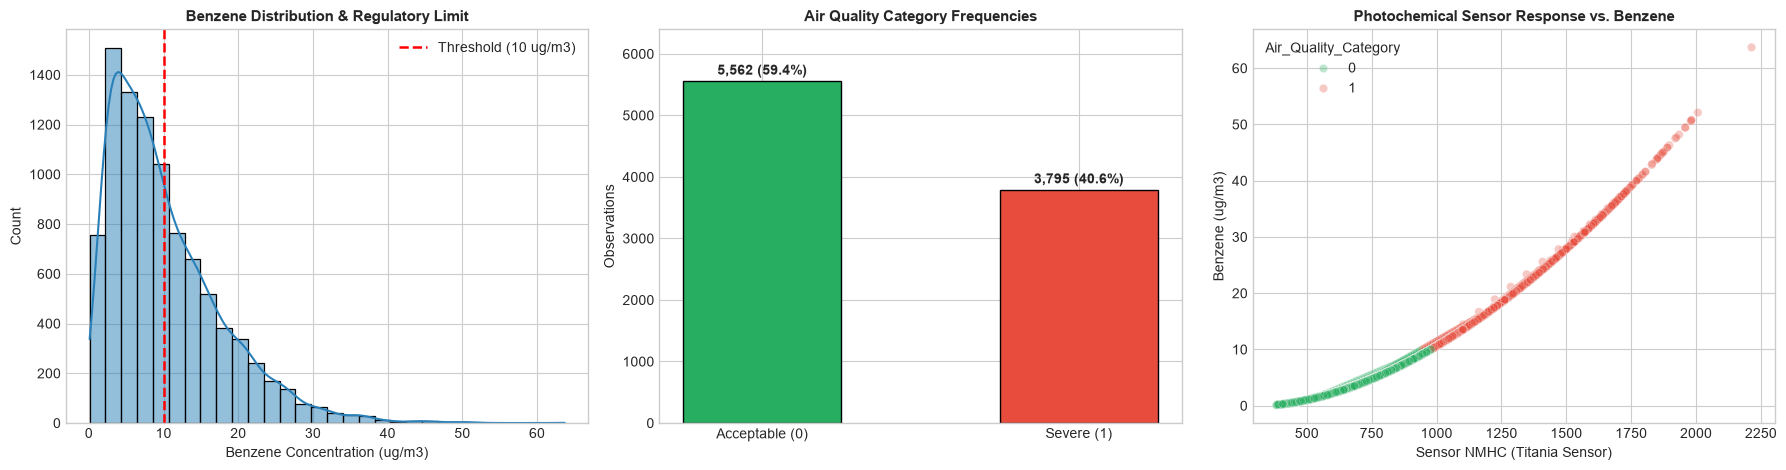

In [ ]:
def plot_bivariate_environmental_dynamics(df: pd.DataFrame):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    
    sns.histplot(df['Benzene_Target'], kde=True, color='#2980b9', bins=30, ax=axes[0])
    axes[0].axvline(10.0, color='red', linestyle='--', linewidth=1.8, label='Threshold (10 ug/m3)')
    axes[0].set_title('Benzene Distribution & Regulatory Limit', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Benzene Concentration (ug/m3)')
    axes[0].legend()
    
    counts = df['Air_Quality_Category'].value_counts()
    axes[1].bar(['Acceptable (0)', 'Severe (1)'], counts.values, color=['#27ae60', '#e74c3c'], edgecolor='black', width=0.5)
    axes[1].set_title('Air Quality Category Frequencies', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('Observations')
    for i, v in enumerate(counts.values):
        axes[1].text(i, v + 100, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')
    axes[1].set_ylim(0, max(counts.values) * 1.15)
    
    sns.scatterplot(data=df, x='Sensor_NMHC', y='Benzene_Target', hue='Air_Quality_Category', palette=['#27ae60', '#e74c3c'], alpha=0.3, ax=axes[2])
    axes[2].set_title('Photochemical Sensor Response vs. Benzene', fontsize=11, fontweight='bold')
    axes[2].set_xlabel('Sensor NMHC (Titania Sensor)')
    axes[2].set_ylabel('Benzene (ug/m3)')
    
    plt.tight_layout()
    plt.show()

plot_bivariate_environmental_dynamics(df_clean)

## 6. Stratified Train-Test Splitting & Feature Standardization
Separate predictor features ($X$) from regression ($y_{\text{reg}}$) and classification ($y_{\text{clf}}$) targets. Partition using an 80/20 train-test ratio, stratified by `Air_Quality_Category`. Apply `StandardScaler` to zero the mean and unit-scale variance across input features.

In [7]:
def split_and_scale_data(df: pd.DataFrame, test_size: float = 0.20, random_state: int = 42):
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler
    
    feature_cols = [c for c in df.columns if c not in ['Benzene_Target', 'Air_Quality_Category']]
    X = df[feature_cols].copy()
    y_reg = df['Benzene_Target'].copy()
    y_clf = df['Air_Quality_Category'].copy()
    
    X_train, X_test, y_reg_train, y_reg_test = train_test_split(
        X, y_reg, test_size=test_size, random_state=random_state, stratify=y_clf
    )
    _, _, y_clf_train, y_clf_test = train_test_split(
        X, y_clf, test_size=test_size, random_state=random_state, stratify=y_clf
    )
    
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols, index=X_train.index)
    X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_cols, index=X_test.index)
    
    print(f"Data Partitioned: Train = {X_train.shape[0]:,} samples | Test = {X_test.shape[0]:,} samples")
    print(f"Input Features Standardized: {len(feature_cols)}")
    return feature_cols, X_train_scaled, X_test_scaled, y_reg_train, y_reg_test, y_clf_train, y_clf_test

feature_cols, X_train_scaled, X_test_scaled, y_reg_train, y_reg_test, y_clf_train, y_clf_test = split_and_scale_data(df_clean)

Data Partitioned: Train = 7,485 samples | Test = 1,872 samples
Input Features Standardized: 11


## 7. Algorithm 1 — Multiple Linear Regression (OLS)
Fit an Ordinary Least Squares Linear Regression model to estimate the baseline transfer coefficients between combustion gas precursors and continuous benzene load. Compute $R^2$, MSE, RMSE, MAE, MAPE, and Residual Variance.

In [ ]:
def evaluate_linear_regression(X_train, y_train, X_test, y_test, feature_names):
    from sklearn.linear_model import LinearRegression
    from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
    
    lr = LinearRegression()
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    
    residuals = y_test.to_numpy() - y_pred
    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    var_res = np.var(residuals)
    
    metrics = {
        'Model': 'Linear Regression',
        'R² Score': round(r2, 4),
        'MSE': round(mse, 4),
        'RMSE': round(rmse, 4),
        'MAE': round(mae, 4),
        'MAPE': round(mape, 4),
        'Var(Residuals)': round(var_res, 4)
    }
    
    print("=== Linear Regression Evaluation Summary ===")
    for k, v in metrics.items():
        print(f"  {k:22s}: {v}")
        
    coeff_df = pd.DataFrame({'Feature': feature_names, 'OLS_Weight': np.round(lr.coef_, 4)}).sort_values(by='OLS_Weight', ascending=False)
    display(coeff_df)
    return lr, metrics, y_pred, coeff_df

lr_model, lr_metrics, y_pred_lr, lr_coeffs = evaluate_linear_regression(
    X_train_scaled, y_reg_train, X_test_scaled, y_reg_test, feature_cols
)

=== Linear Regression Evaluation Summary ===
  Model                 : Linear Regression
  R² Score              : 0.9782
  MSE                   : 1.25
  RMSE                  : 1.118
  MAE                   : 0.8274
  MAPE                  : 0.2186
  Var(Residuals)        : 1.2481


,Feature,OLS_Weight
2,Sensor_NMHC,7.8662
4,Sensor_NOx,1.0153
10,Absolute_Humidity,0.5440
3,NOx_True,0.4344
0,CO_True,0.2973
1,Sensor_CO,0.2768
6,Sensor_NO2,-0.0392
7,Sensor_O3,-0.0940
9,Relative_Humidity,-0.4842
5,NO2_True,-0.5068


## 8. Linear Regression Diagnostics (Parity & Residual Plots)
Plot predicted versus actual benzene concentrations along the $45^\circ$ reference line and inspect the residual distribution for non-linearity and heteroscedasticity.

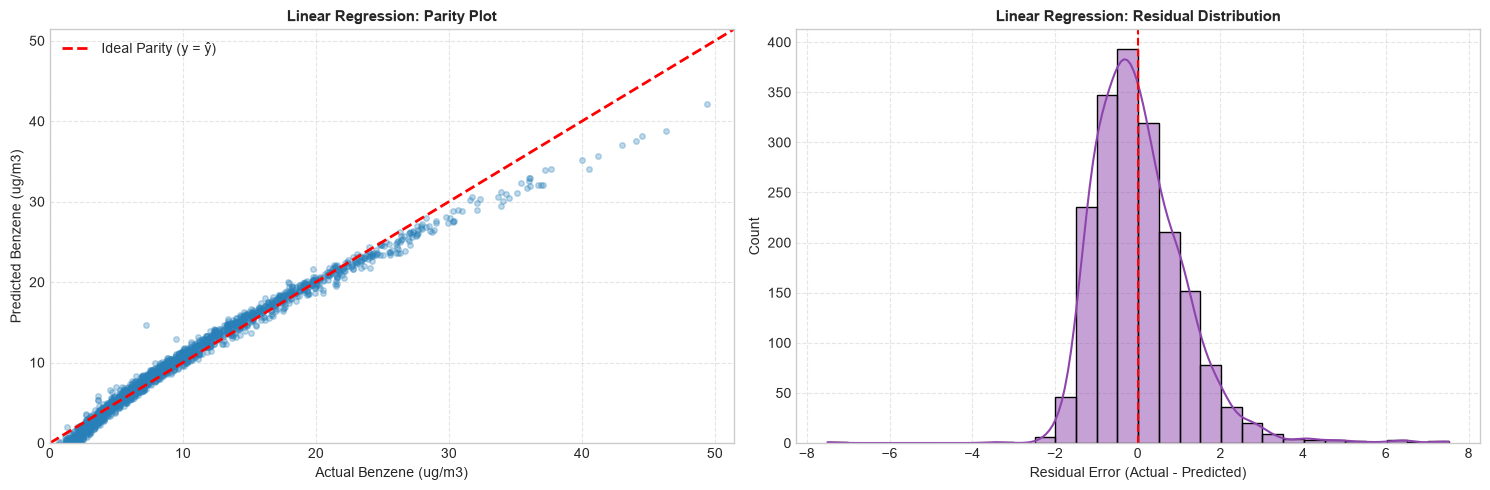

In [ ]:
def plot_regression_diagnostics(y_test, y_pred, model_label: str = 'Linear Regression'):
    residuals = y_test.to_numpy() - y_pred
    
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    axes[0].scatter(y_test, y_pred, alpha=0.3, color='#2980b9', s=16)
    lims = [0, max(y_test.max(), y_pred.max()) + 2]
    axes[0].plot(lims, lims, 'r--', lw=2, label='Ideal Parity (y = ŷ)')
    axes[0].set_title(f'{model_label}: Parity Plot', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Actual Benzene (ug/m3)')
    axes[0].set_ylabel('Predicted Benzene (ug/m3)')
    axes[0].set_xlim(lims)
    axes[0].set_ylim(lims)
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    sns.histplot(residuals, kde=True, color='#8e44ad', bins=30, ax=axes[1])
    axes[1].axvline(0, color='red', linestyle='--', lw=1.5)
    axes[1].set_title(f'{model_label}: Residual Distribution', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Residual Error (Actual - Predicted)')
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

plot_regression_diagnostics(y_reg_test, y_pred_lr, 'Linear Regression')

## 9. Algorithm 2 — Polynomial Regression (Degrees 2 & Interaction Dynamics)
Model non-linear secondary photochemical transformations and cross-interaction terms between ambient Temperature, Relative Humidity, and gaseous sensors using a 2nd-degree polynomial expansion.

In [10]:
def evaluate_polynomial_regression(X_train, y_train, X_test, y_test, degree: int = 2):
    from sklearn.preprocessing import PolynomialFeatures
    from sklearn.linear_model import LinearRegression
    from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
    
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    
    poly_lr = LinearRegression()
    poly_lr.fit(X_train_poly, y_train)
    y_pred = poly_lr.predict(X_test_poly)
    
    residuals = y_test.to_numpy() - y_pred
    metrics = {
        'Model': f'Polynomial Regression (Deg {degree})',
        'R² Score': round(r2_score(y_test, y_pred), 4),
        'MSE': round(mean_squared_error(y_test, y_pred), 4),
        'RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred)), 4),
        'MAE': round(mean_absolute_error(y_test, y_pred), 4),
        'MAPE': round(mean_absolute_percentage_error(y_test, y_pred), 4),
        'Var(Residuals)': round(np.var(residuals), 4),
        'Expanded Features': X_train_poly.shape[1]
    }
    
    print("=== Polynomial Regression Evaluation Summary ===")
    for k, v in metrics.items():
        print(f"  {k:22s}: {v}")
    return poly, poly_lr, metrics, y_pred

poly_trans, poly_model, poly_metrics, y_pred_poly = evaluate_polynomial_regression(
    X_train_scaled, y_reg_train, X_test_scaled, y_reg_test, degree=2
)

=== Polynomial Regression Evaluation Summary ===
  Model                 : Polynomial Regression (Deg 2)
  R² Score              : 0.9998
  MSE                   : 0.0089
  RMSE                  : 0.0942
  MAE                   : 0.0548
  MAPE                  : 0.013
  Var(Residuals)        : 0.0089
  Expanded Features     : 77


## 10. Algorithm 3A — Logistic Regression (Without PCA)
Train a standardized Logistic Regression classifier on `Air_Quality_Category` (0: Acceptable vs. 1: Severe). Extract log-odds weights to pinpoint the primary drivers of dangerous pollution exceedance.

In [11]:
def evaluate_logistic_regression_raw(X_train, y_train, X_test, y_test, feature_names):
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
    
    clf = LogisticRegression(max_iter=1000, random_state=42)
    clf.fit(X_train, y_train)
    
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    
    metrics = {
        'Model': 'Logistic Regression (No PCA)',
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
    }
    
    print("=== Logistic Regression (Raw Features) Metrics ===")
    for k, v in metrics.items():
        print(f"  {k:15s}: {v}")
        
    weights_df = pd.DataFrame({'Feature': feature_names, 'Log_Odds_Weight': np.round(clf.coef_[0], 4)}).sort_values(by='Log_Odds_Weight', key=abs, ascending=False)
    display(weights_df)
    return clf, metrics, y_pred, y_prob, weights_df

logreg_raw_model, logreg_raw_metrics, y_pred_log_raw, y_prob_log_raw, logreg_weights = evaluate_logistic_regression_raw(
    X_train_scaled, y_clf_train, X_test_scaled, y_clf_test, feature_cols
)

=== Logistic Regression (Raw Features) Metrics ===
  Model          : Logistic Regression (No PCA)
  Accuracy       : 0.9931
  Precision      : 0.9934
  Recall         : 0.9895
  F1-Score       : 0.9914
  ROC-AUC        : 0.9998


,Feature,Log_Odds_Weight
2,Sensor_NMHC,14.8816
6,Sensor_NO2,1.1405
3,NOx_True,0.6927
7,Sensor_O3,0.5403
10,Absolute_Humidity,-0.4037
9,Relative_Humidity,-0.3933
1,Sensor_CO,0.3030
4,Sensor_NOx,-0.2701
8,Temperature,0.0857
0,CO_True,-0.0759


## 11. Algorithm 3B — Logistic Regression (With 3-Component PCA)
Compress the 11 collinear environmental features into 3 orthogonal Principal Components using PCA.  Evaluate classification stability, scree variance, and compare against raw feature modeling.

In [12]:
def evaluate_logistic_regression_pca(X_train, y_train, X_test, y_test, n_components: int = 3):
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
    
    pca = PCA(n_components=n_components, random_state=42)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)
    
    exp_var = pca.explained_variance_ratio_
    cum_var = np.cumsum(exp_var)
    print(f"Explained Variance per PC : {np.round(exp_var * 100, 2)}")
    print(f"Cumulative Explained Var  : {cum_var[-1] * 100:.2f}%\n")
    
    clf = LogisticRegression(max_iter=1000, random_state=42)
    clf.fit(X_train_pca, y_train)
    
    y_pred = clf.predict(X_test_pca)
    y_prob = clf.predict_proba(X_test_pca)[:, 1]
    
    metrics = {
        'Model': f'Logistic Regression ({n_components} PCs)',
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
    }
    
    print("=== Logistic Regression (With PCA) Metrics ===")
    for k, v in metrics.items():
        print(f"  {k:15s}: {v}")
    return pca, clf, metrics, y_pred, y_prob

pca_transformer, logreg_pca_model, logreg_pca_metrics, y_pred_log_pca, y_prob_log_pca = evaluate_logistic_regression_pca(
    X_train_scaled, y_clf_train, X_test_scaled, y_clf_test, n_components=3
)

Explained Variance per PC : [52.92 22.22 12.15]
Cumulative Explained Var  : 87.30%

=== Logistic Regression (With PCA) Metrics ===
  Model          : Logistic Regression (3 PCs)
  Accuracy       : 0.9482
  Precision      : 0.9402
  Recall         : 0.9315
  F1-Score       : 0.9358
  ROC-AUC        : 0.99


## 12. Comparison of Logistic Regression (Raw vs. PCA)
Plot a side-by-side comparison of Confusion Matrices and ROC curves between raw feature Logistic Regression and 3-component PCA Logistic Regression.

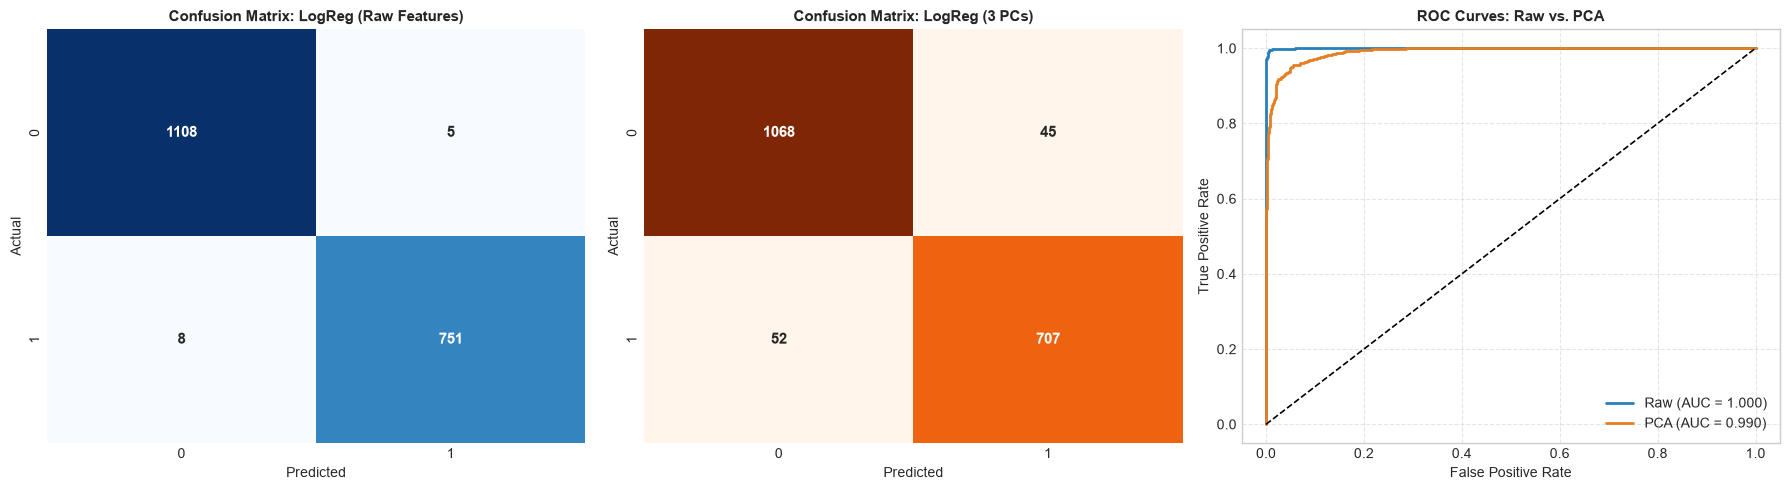

In [ ]:
def plot_logistic_comparison(y_test, pred_raw, prob_raw, pred_pca, prob_pca):
    from sklearn.metrics import confusion_matrix, roc_curve, auc
    
    cm_raw = confusion_matrix(y_test, pred_raw)
    cm_pca = confusion_matrix(y_test, pred_pca)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    sns.heatmap(cm_raw, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0], annot_kws={'size': 11, 'weight': 'bold'})
    axes[0].set_title('Confusion Matrix: LogReg (Raw Features)', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Actual')
    
    sns.heatmap(cm_pca, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=axes[1], annot_kws={'size': 11, 'weight': 'bold'})
    axes[1].set_title('Confusion Matrix: LogReg (3 PCs)', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('Actual')
    
    fpr_raw, tpr_raw, _ = roc_curve(y_test, prob_raw)
    fpr_pca, tpr_pca, _ = roc_curve(y_test, prob_pca)
    axes[2].plot(fpr_raw, tpr_raw, color='#2980b9', lw=2, label=f'Raw (AUC = {auc(fpr_raw, tpr_raw):.3f})')
    axes[2].plot(fpr_pca, tpr_pca, color='#e67e22', lw=2, label=f'PCA (AUC = {auc(fpr_pca, tpr_pca):.3f})')
    axes[2].plot([0, 1], [0, 1], 'k--', lw=1.2)
    axes[2].set_title('ROC Curves: Raw vs. PCA', fontsize=11, fontweight='bold')
    axes[2].set_xlabel('False Positive Rate')
    axes[2].set_ylabel('True Positive Rate')
    axes[2].legend(loc='lower right')
    axes[2].grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

plot_logistic_comparison(y_clf_test, y_pred_log_raw, y_prob_log_raw, y_pred_log_pca, y_prob_log_pca)

## 13. Algorithm 4A — K-Nearest Neighbors Regression
Fit a K-NN Regressor estimating continuous Benzene load using inverse-distance weighting across neighboring atmospheric states. Tune $K \in [1, 20]$ to map neighborhood error sensitivity.

In [ ]:
def tune_knn_regressor(X_train, y_train, X_test, y_test, k_range=range(1, 21)):
    from sklearn.neighbors import KNeighborsRegressor
    from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
    
    k_vals, r2_scores, rmse_scores = [], [], []
    k_vals_list = list(k_range)
    
    for k in k_vals_list:
        knn = KNeighborsRegressor(n_neighbors=k, weights='distance')
        knn.fit(X_train, y_train)
        pred = knn.predict(X_test)
        
        k_vals.append(k)
        r2_scores.append(r2_score(y_test, pred))
        rmse_scores.append(np.sqrt(mean_squared_error(y_test, pred)))
        
    best_k = k_vals[int(np.argmax(r2_scores))]
    
    best_knn_reg = KNeighborsRegressor(n_neighbors=best_k, weights='distance')
    best_knn_reg.fit(X_train, y_train)
    y_pred = best_knn_reg.predict(X_test)
    
    residuals = y_test.to_numpy() - y_pred
    metrics = {
        'Model': f'K-NN Regressor (K={best_k})',
        'R² Score': round(r2_score(y_test, y_pred), 4),
        'MSE': round(mean_squared_error(y_test, y_pred), 4),
        'RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred)), 4),
        'MAE': round(mean_absolute_error(y_test, y_pred), 4),
        'MAPE': round(mean_absolute_percentage_error(y_test, y_pred), 4),
        'Var(Residuals)': round(np.var(residuals), 4)
    }
    
    print(f"Optimal K: {best_k} with R²: {metrics['R² Score']} and RMSE: {metrics['RMSE']}")
    return best_knn_reg, metrics, y_pred, k_vals, r2_scores, rmse_scores

knn_reg_model, knn_reg_metrics, y_pred_knn_reg, k_range_reg, r2_k_reg, rmse_k_reg = tune_knn_regressor(
    X_train_scaled, y_reg_train, X_test_scaled, y_reg_test
)

Optimal K: 5 with R²: 0.9819 and RMSE: 1.0196


## 14. Algorithm 4B — K-Nearest Neighbors Classification
Sweep $K \in [1, 25]$ for K-NN classification predicting `Air_Quality_Category` via majority vote to analyze decision boundary sensitivity.

In [ ]:
def tune_knn_classifier(X_train, y_train, X_test, y_test, k_range=range(1, 26)):
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
    
    k_vals, acc_scores, f1_scores = [], [], []
    k_vals_list = list(k_range)
    
    for k in k_vals_list:
        clf = KNeighborsClassifier(n_neighbors=k, weights='distance')
        clf.fit(X_train, y_train)
        pred = clf.predict(X_test)
        
        k_vals.append(k)
        acc_scores.append(accuracy_score(y_test, pred))
        f1_scores.append(f1_score(y_test, pred))
        
    best_k = k_vals[int(np.argmax(f1_scores))]
    
    best_knn_clf = KNeighborsClassifier(n_neighbors=best_k, weights='distance')
    best_knn_clf.fit(X_train, y_train)
    y_pred = best_knn_clf.predict(X_test)
    y_prob = best_knn_clf.predict_proba(X_test)[:, 1]
    
    metrics = {
        'Model': f'K-NN Classifier (K={best_k})',
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
    }
    
    print(f"Optimal K: {best_k} with Accuracy: {metrics['Accuracy']} and F1: {metrics['F1-Score']}")
    return best_knn_clf, metrics, y_pred, y_prob, k_vals, acc_scores, f1_scores

knn_clf_model, knn_clf_metrics, y_pred_knn_clf, y_prob_knn_clf, k_range_clf, acc_k_clf, f1_k_clf = tune_knn_classifier(
    X_train_scaled, y_clf_train, X_test_scaled, y_clf_test
)

Optimal K: 13 with Accuracy: 0.9696 and F1: 0.9621


## 15. K-NN Tuning Curves (Regression Error vs. Classification Accuracy)
Visualize performance trajectories as a function of neighborhood size ($K$) for both regression (RMSE) and classification (Accuracy & F1).

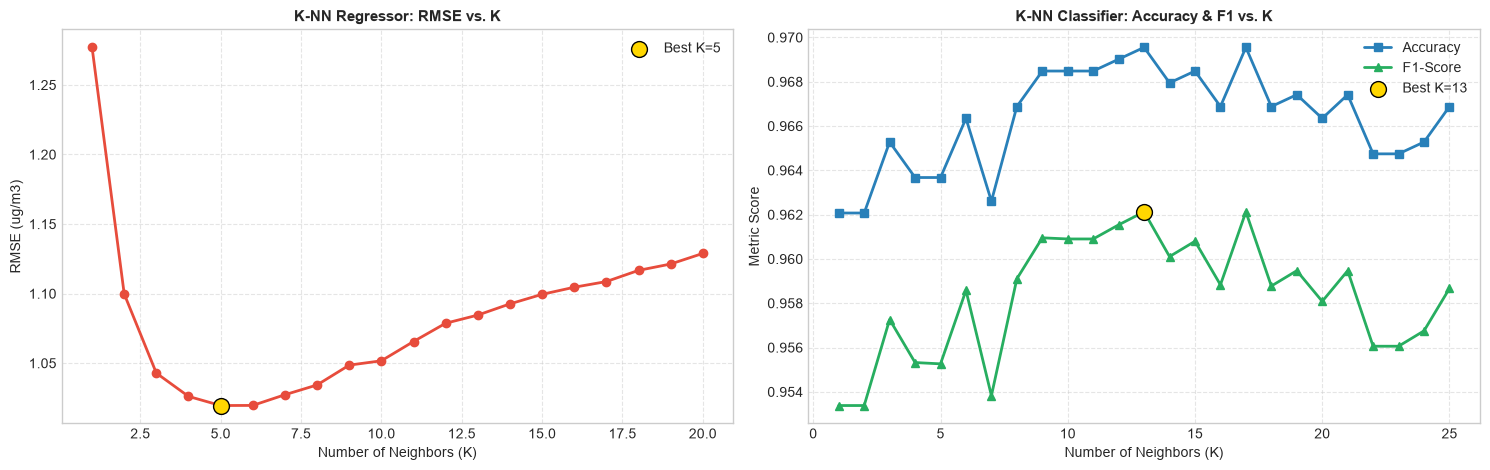

In [ ]:
def plot_knn_tuning_curves(k_reg, rmse_reg, k_clf, acc_clf, f1_clf):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    
    axes[0].plot(k_reg, rmse_reg, marker='o', color='#e74c3c', lw=2)
    best_k_r = k_reg[int(np.argmin(rmse_reg))]
    axes[0].scatter(best_k_r, min(rmse_reg), color='gold', s=130, edgecolor='black', zorder=5, label=f'Best K={best_k_r}')
    axes[0].set_title('K-NN Regressor: RMSE vs. K', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Number of Neighbors (K)')
    axes[0].set_ylabel('RMSE (ug/m3)')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    axes[1].plot(k_clf, acc_clf, marker='s', color='#2980b9', lw=2, label='Accuracy')
    axes[1].plot(k_clf, f1_clf, marker='^', color='#27ae60', lw=2, label='F1-Score')
    best_k_c = k_clf[int(np.argmax(f1_clf))]
    axes[1].scatter(best_k_c, max(f1_clf), color='gold', s=130, edgecolor='black', zorder=5, label=f'Best K={best_k_c}')
    axes[1].set_title('K-NN Classifier: Accuracy & F1 vs. K', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Number of Neighbors (K)')
    axes[1].set_ylabel('Metric Score')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

plot_knn_tuning_curves(k_range_reg, rmse_k_reg, k_range_clf, acc_k_clf, f1_k_clf)

## 16. Algorithm 5 — Unsupervised K-Means Clustering (Elbow Method & Silhouette Validation)
Strip all target labels and cluster the continuous sensor telemetry using `KMeans` with `k-means++` initialization. Validate cluster tightness using the Elbow Method (WCSS/Inertia) and Silhouette Analysis to identify natural atmospheric regimes.

In [ ]:
def evaluate_kmeans_clustering(X, k_range=range(2, 9)):
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
    
    wcss, sil_scores = [], []
    k_vals = list(k_range)
    
    print("Evaluating K-Means across k ∈ [2, 8]...")
    for k in k_vals:
        km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
        labels = km.fit_predict(X)
        wcss.append(km.inertia_)
        sil = silhouette_score(X, labels, sample_size=2500, random_state=42)
        sil_scores.append(sil)
        print(f"k = {k} | Inertia: {km.inertia_:,.1f} | Silhouette: {sil:.4f}")
        
    cluster_eval_df = pd.DataFrame({'k': k_vals, 'Inertia (WCSS)': np.round(wcss, 1), 'Silhouette_Score': np.round(sil_scores, 4)})
    display(cluster_eval_df)
    
    final_km = KMeans(n_clusters=3, init='k-means++', n_init=15, random_state=42)
    final_labels = final_km.fit_predict(X)
    return final_km, final_labels, cluster_eval_df

kmeans_model, cluster_labels_km, kmeans_eval_df = evaluate_kmeans_clustering(X_train_scaled)

Evaluating K-Means across k ∈ [2, 8]...
k = 2 | Inertia: 53,744.9 | Silhouette: 0.3100
k = 3 | Inertia: 43,803.8 | Silhouette: 0.2344
k = 4 | Inertia: 37,974.8 | Silhouette: 0.2277
k = 5 | Inertia: 33,968.1 | Silhouette: 0.2096
k = 6 | Inertia: 30,898.9 | Silhouette: 0.2077
k = 7 | Inertia: 28,656.3 | Silhouette: 0.2114
k = 8 | Inertia: 26,740.8 | Silhouette: 0.2063


,k,Inertia (WCSS),Silhouette_Score
0,2,53744.9,0.3100
1,3,43803.8,0.2344
2,4,37974.8,0.2277
3,5,33968.1,0.2096
4,6,30898.9,0.2077
5,7,28656.3,0.2114
6,8,26740.8,0.2063


## 17. Clustering Visualizations (Elbow Curve, Silhouette & PCA Regime Projection)
Plot the WCSS Elbow curve, Silhouette progression, and project the 3 identified atmospheric regimes onto a 2D PCA projection.

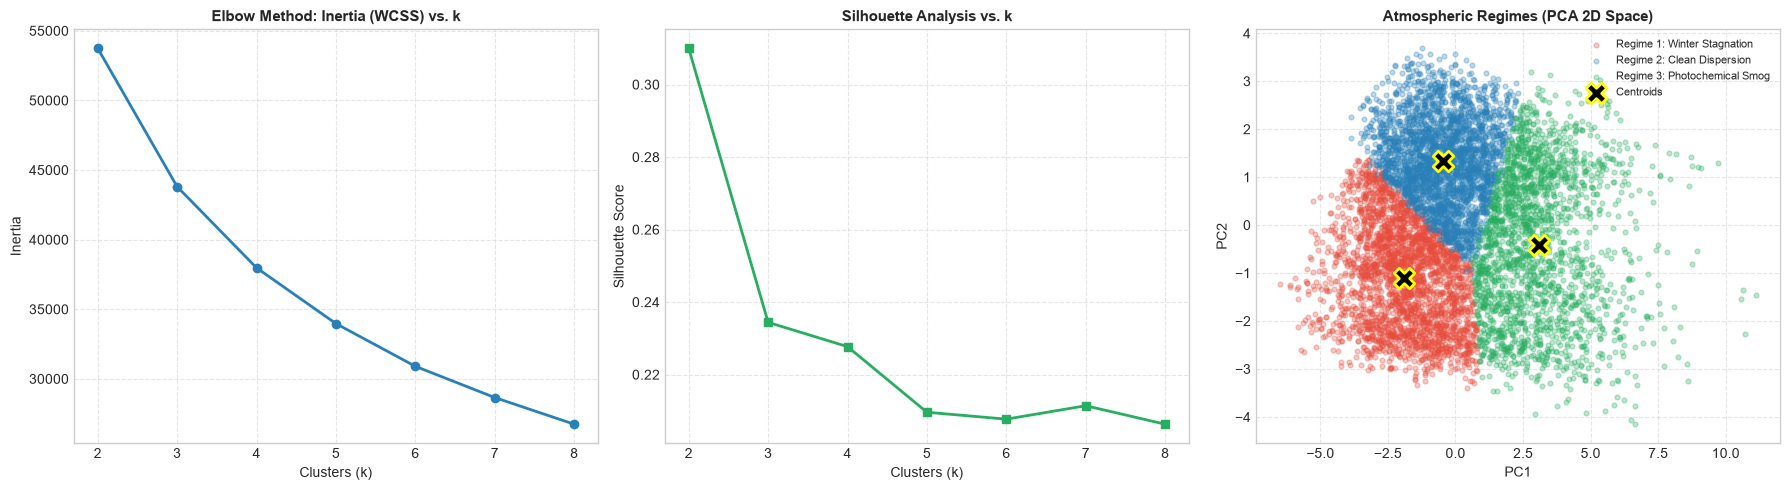

In [ ]:
def plot_clustering_diagnostics(eval_df, X, labels, kmeans_model):
    from sklearn.decomposition import PCA
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    axes[0].plot(eval_df['k'], eval_df['Inertia (WCSS)'], marker='o', color='#2980b9', lw=2)
    axes[0].set_title('Elbow Method: Inertia (WCSS) vs. k', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Clusters (k)')
    axes[0].set_ylabel('Inertia')
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    axes[1].plot(eval_df['k'], eval_df['Silhouette_Score'], marker='s', color='#27ae60', lw=2)
    axes[1].set_title('Silhouette Analysis vs. k', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Clusters (k)')
    axes[1].set_ylabel('Silhouette Score')
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X)
    centers_pca = pca.transform(kmeans_model.cluster_centers_)
    
    colors = ['#e74c3c', '#2980b9', '#27ae60']
    regime_names = ['Regime 1: Winter Stagnation', 'Regime 2: Clean Dispersion', 'Regime 3: Photochemical Smog']
    
    for c_idx in range(3):
        mask = (labels == c_idx)
        axes[2].scatter(X_pca[mask, 0], X_pca[mask, 1], s=12, alpha=0.3, color=colors[c_idx], label=regime_names[c_idx])
    axes[2].scatter(centers_pca[:, 0], centers_pca[:, 1], c='black', marker='X', s=220, edgecolor='yellow', lw=2, label='Centroids')
    axes[2].set_title('Atmospheric Regimes (PCA 2D Space)', fontsize=11, fontweight='bold')
    axes[2].set_xlabel('PC1')
    axes[2].set_ylabel('PC2')
    axes[2].legend(fontsize=8, loc='upper right')
    axes[2].grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

plot_clustering_diagnostics(kmeans_eval_df, X_train_scaled, cluster_labels_km, kmeans_model)

## 18. Algorithm 6A — Support Vector Regression ($\epsilon$-SVR)
Train an $\epsilon$-SVR model with an RBF kernel. The $\epsilon$-tube parameter allows the model to ignore minor sensor turbulence and noise below threshold drift. Compute continuous regression metrics and residual variance.

In [21]:
def evaluate_svr(X_train, y_train, X_test, y_test, C: float = 10.0, gamma: float = 0.05, epsilon: float = 0.1):
    from sklearn.svm import SVR
    from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
    
    svr = SVR(C=C, gamma=gamma, epsilon=epsilon, kernel='rbf')
    svr.fit(X_train, y_train)
    y_pred = svr.predict(X_test)
    
    residuals = y_test.to_numpy() - y_pred
    metrics = {
        'Model': f'SVR (C={C}, g={gamma})',
        'R² Score': round(r2_score(y_test, y_pred), 4),
        'MSE': round(mean_squared_error(y_test, y_pred), 4),
        'RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred)), 4),
        'MAE': round(mean_absolute_error(y_test, y_pred), 4),
        'MAPE': round(mean_absolute_percentage_error(y_test, y_pred), 4),
        'Var(Residuals)': round(np.var(residuals), 4),
        'Support Vectors': svr.support_.shape[0]
    }
    
    print("=== Support Vector Regression (SVR) Metrics ===")
    for k, v in metrics.items():
        print(f"  {k:22s}: {v}")
    return svr, metrics, y_pred

svr_model, svr_metrics, y_pred_svr = evaluate_svr(
    X_train_scaled, y_reg_train, X_test_scaled, y_reg_test, C=10.0, gamma=0.05, epsilon=0.1
)

=== Support Vector Regression (SVR) Metrics ===
  Model                 : SVR (C=10.0, g=0.05)
  R² Score              : 0.9995
  MSE                   : 0.0312
  RMSE                  : 0.1766
  MAE                   : 0.0694
  MAPE                  : 0.0124
  Var(Residuals)        : 0.0312
  Support Vectors       : 1259


## 19. Algorithm 6B — Support Vector Classifier (SVC)
Fit a maximum-margin Support Vector Classifier (SVC) with an RBF kernel to separate hazardous exceedance days from acceptable air quality periods.

In [22]:
def evaluate_svc(X_train, y_train, X_test, y_test, C: float = 10.0, gamma: float = 0.05):
    from sklearn.svm import SVC
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
    
    svc = SVC(C=C, gamma=gamma, kernel='rbf', probability=True, random_state=42)
    svc.fit(X_train, y_train)
    
    y_pred = svc.predict(X_test)
    y_prob = svc.predict_proba(X_test)[:, 1]
    
    metrics = {
        'Model': f'SVC (C={C}, g={gamma})',
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4),
        'Support Vectors': svc.support_.shape[0]
    }
    
    print("=== Support Vector Classifier (SVC) Metrics ===")
    for k, v in metrics.items():
        print(f"  {k:15s}: {v}")
    return svc, metrics, y_pred, y_prob

svc_model, svc_metrics, y_pred_svc, y_prob_svc = evaluate_svc(
    X_train_scaled, y_clf_train, X_test_scaled, y_clf_test, C=10.0, gamma=0.05
)

=== Support Vector Classifier (SVC) Metrics ===
  Model          : SVC (C=10.0, g=0.05)
  Accuracy       : 0.9941
  Precision      : 0.9908
  Recall         : 0.9947
  F1-Score       : 0.9928
  ROC-AUC        : 0.9999
  Support Vectors: 424


## 20. Algorithm 7 — Naive Bayes (GaussianNB)
Fit class-conditional Gaussian distributions on the continuous sensor telemetry features. Analyze model classification efficacy and discuss where correlated co-pollutants challenge the conditional independence assumption.

In [23]:
def evaluate_gaussian_naive_bayes(X_train, y_train, X_test, y_test):
    from sklearn.naive_bayes import GaussianNB
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
    
    gnb = GaussianNB()
    gnb.fit(X_train, y_train)
    
    y_pred = gnb.predict(X_test)
    y_prob = gnb.predict_proba(X_test)[:, 1]
    
    metrics = {
        'Model': 'Gaussian Naive Bayes',
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
    }
    
    print("=== Gaussian Naive Bayes Metrics ===")
    for k, v in metrics.items():
        print(f"  {k:15s}: {v}")
    return gnb, metrics, y_pred, y_prob

gnb_model, gnb_metrics, y_pred_gnb, y_prob_gnb = evaluate_gaussian_naive_bayes(
    X_train_scaled, y_clf_train, X_test_scaled, y_clf_test
)

=== Gaussian Naive Bayes Metrics ===
  Model          : Gaussian Naive Bayes
  Accuracy       : 0.9284
  Precision      : 0.9085
  Recall         : 0.9157
  F1-Score       : 0.9121
  ROC-AUC        : 0.9827


## 21. Algorithm 8A — Decision Tree Regressor
Train a regularized Decision Tree Regressor to produce piecewise-constant partitions of continuous benzene concentration. Evaluate regression metrics and extract feature importance rankings.

In [24]:
def evaluate_decision_tree_regressor(X_train, y_train, X_test, y_test, feature_names, max_depth: int = 8):
    from sklearn.tree import DecisionTreeRegressor
    from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
    
    dt_reg = DecisionTreeRegressor(max_depth=max_depth, min_samples_split=5, random_state=42)
    dt_reg.fit(X_train, y_train)
    y_pred = dt_reg.predict(X_test)
    
    residuals = y_test.to_numpy() - y_pred
    metrics = {
        'Model': f'Decision Tree Regressor (Depth {max_depth})',
        'R² Score': round(r2_score(y_test, y_pred), 4),
        'MSE': round(mean_squared_error(y_test, y_pred), 4),
        'RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred)), 4),
        'MAE': round(mean_absolute_error(y_test, y_pred), 4),
        'MAPE': round(mean_absolute_percentage_error(y_test, y_pred), 4),
        'Var(Residuals)': round(np.var(residuals), 4)
    }
    
    print("=== Decision Tree Regressor Metrics ===")
    for k, v in metrics.items():
        print(f"  {k:22s}: {v}")
        
    feat_imp = pd.DataFrame({'Feature': feature_names, 'Importance': np.round(dt_reg.feature_importances_, 4)}).sort_values(by='Importance', ascending=False)
    display(feat_imp.head(6))
    return dt_reg, metrics, y_pred, feat_imp

dt_reg_model, dt_reg_metrics, y_pred_dt_reg, dt_reg_importances = evaluate_decision_tree_regressor(
    X_train_scaled, y_reg_train, X_test_scaled, y_reg_test, feature_cols, max_depth=8
)

=== Decision Tree Regressor Metrics ===
  Model                 : Decision Tree Regressor (Depth 8)
  R² Score              : 0.9998
  MSE                   : 0.0141
  RMSE                  : 0.1189
  MAE                   : 0.0541
  MAPE                  : 0.0084
  Var(Residuals)        : 0.0141


,Feature,Importance
2,Sensor_NMHC,0.9993
1,Sensor_CO,0.0007
0,CO_True,0.0000
3,NOx_True,0.0000
4,Sensor_NOx,0.0000
5,NO2_True,0.0000


## 22. Algorithm 8B — Decision Tree Classifier
Fit a regularized Decision Tree Classifier to uncover statutory regulatory rules (e.g., if titania sensor exceeds threshold $\to$ Severe). Evaluate classification metrics and Gini feature importances.

In [25]:
def evaluate_decision_tree_classifier(X_train, y_train, X_test, y_test, feature_names, max_depth: int = 8):
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
    
    dt_clf = DecisionTreeClassifier(max_depth=max_depth, min_samples_split=5, random_state=42)
    dt_clf.fit(X_train, y_train)
    
    y_pred = dt_clf.predict(X_test)
    y_prob = dt_clf.predict_proba(X_test)[:, 1]
    
    metrics = {
        'Model': f'Decision Tree Classifier (Depth {max_depth})',
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
    }
    
    print("=== Decision Tree Classifier Metrics ===")
    for k, v in metrics.items():
        print(f"  {k:15s}: {v}")
        
    feat_imp = pd.DataFrame({'Feature': feature_names, 'Gini_Importance': np.round(dt_clf.feature_importances_, 4)}).sort_values(by='Gini_Importance', ascending=False)
    display(feat_imp.head(6))
    return dt_clf, metrics, y_pred, y_prob, feat_imp

dt_clf_model, dt_clf_metrics, y_pred_dt_clf, y_prob_dt_clf, dt_clf_importances = evaluate_decision_tree_classifier(
    X_train_scaled, y_clf_train, X_test_scaled, y_clf_test, feature_cols, max_depth=8
)

=== Decision Tree Classifier Metrics ===
  Model          : Decision Tree Classifier (Depth 8)
  Accuracy       : 0.9984
  Precision      : 1.0
  Recall         : 0.996
  F1-Score       : 0.998
  ROC-AUC        : 0.9987


,Feature,Gini_Importance
2,Sensor_NMHC,0.9987
7,Sensor_O3,0.0009
5,NO2_True,0.0003
3,NOx_True,0.0001
0,CO_True,0.0000
1,Sensor_CO,0.0000


## 23. Master Regression Benchmark Leaderboard
Aggregate all regression models into a unified comparative leaderboard tracking $R^2$, MSE, RMSE, MAE, MAPE, and Residual Variance.

In [26]:
def compile_regression_leaderboard(m1, m2, m3, m4, m5):
    all_metrics = [m1, m2, m3, m4, m5]
    leaderboard = pd.DataFrame(all_metrics).sort_values(by=['R² Score', 'RMSE'], ascending=[False, True]).reset_index(drop=True)
    
    print("=" * 80)
    print("MASTER REGRESSION ALGORITHM LEADERBOARD")
    print("=" * 80)
    display(leaderboard)
    return leaderboard

reg_leaderboard = compile_regression_leaderboard(
    lr_metrics, poly_metrics, knn_reg_metrics, svr_metrics, dt_reg_metrics
)

MASTER REGRESSION ALGORITHM LEADERBOARD


,Model,R² Score,MSE,RMSE,MAE,MAPE,Var(Residuals),Expanded Features,Support Vectors
0,Polynomial Regression (Deg 2),0.9998,0.0089,0.0942,0.0548,0.0130,0.0089,77.0,NaN
1,Decision Tree Regressor (Depth 8),0.9998,0.0141,0.1189,0.0541,0.0084,0.0141,NaN,NaN
2,"SVR (C=10.0, g=0.05)",0.9995,0.0312,0.1766,0.0694,0.0124,0.0312,NaN,1259.0
3,K-NN Regressor (K=5),0.9819,1.0395,1.0196,0.6340,0.0763,1.0288,NaN,NaN
4,Linear Regression,0.9782,1.2500,1.1180,0.8274,0.2186,1.2481,NaN,NaN


## 24. Master Classification Benchmark Leaderboard
Aggregate all classification models into a unified comparative leaderboard tracking Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

In [27]:
def compile_classification_leaderboard(m1, m2, m3, m4, m5, m6):
    all_metrics = [m1, m2, m3, m4, m5, m6]
    leaderboard = pd.DataFrame(all_metrics).sort_values(by=['F1-Score', 'Accuracy'], ascending=[False, False]).reset_index(drop=True)
    
    print("=" * 80)
    print("MASTER CLASSIFICATION ALGORITHM LEADERBOARD")
    print("=" * 80)
    display(leaderboard)
    return leaderboard

clf_leaderboard = compile_classification_leaderboard(
    logreg_raw_metrics, logreg_pca_metrics, knn_clf_metrics, svc_metrics, gnb_metrics, dt_clf_metrics
)

MASTER CLASSIFICATION ALGORITHM LEADERBOARD


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Support Vectors
0,Decision Tree Classifier (Depth 8),0.9984,1.0000,0.9960,0.9980,0.9987,NaN
1,"SVC (C=10.0, g=0.05)",0.9941,0.9908,0.9947,0.9928,0.9999,424.0
2,Logistic Regression (No PCA),0.9931,0.9934,0.9895,0.9914,0.9998,NaN
3,K-NN Classifier (K=13),0.9696,0.9705,0.9539,0.9621,0.9971,NaN
4,Logistic Regression (3 PCs),0.9482,0.9402,0.9315,0.9358,0.9900,NaN
5,Gaussian Naive Bayes,0.9284,0.9085,0.9157,0.9121,0.9827,NaN


## 25. Master Graphical Comparison of Models
Render bar charts comparing $R^2$ and RMSE across all regression models, alongside Accuracy and F1-Score across all classification models.

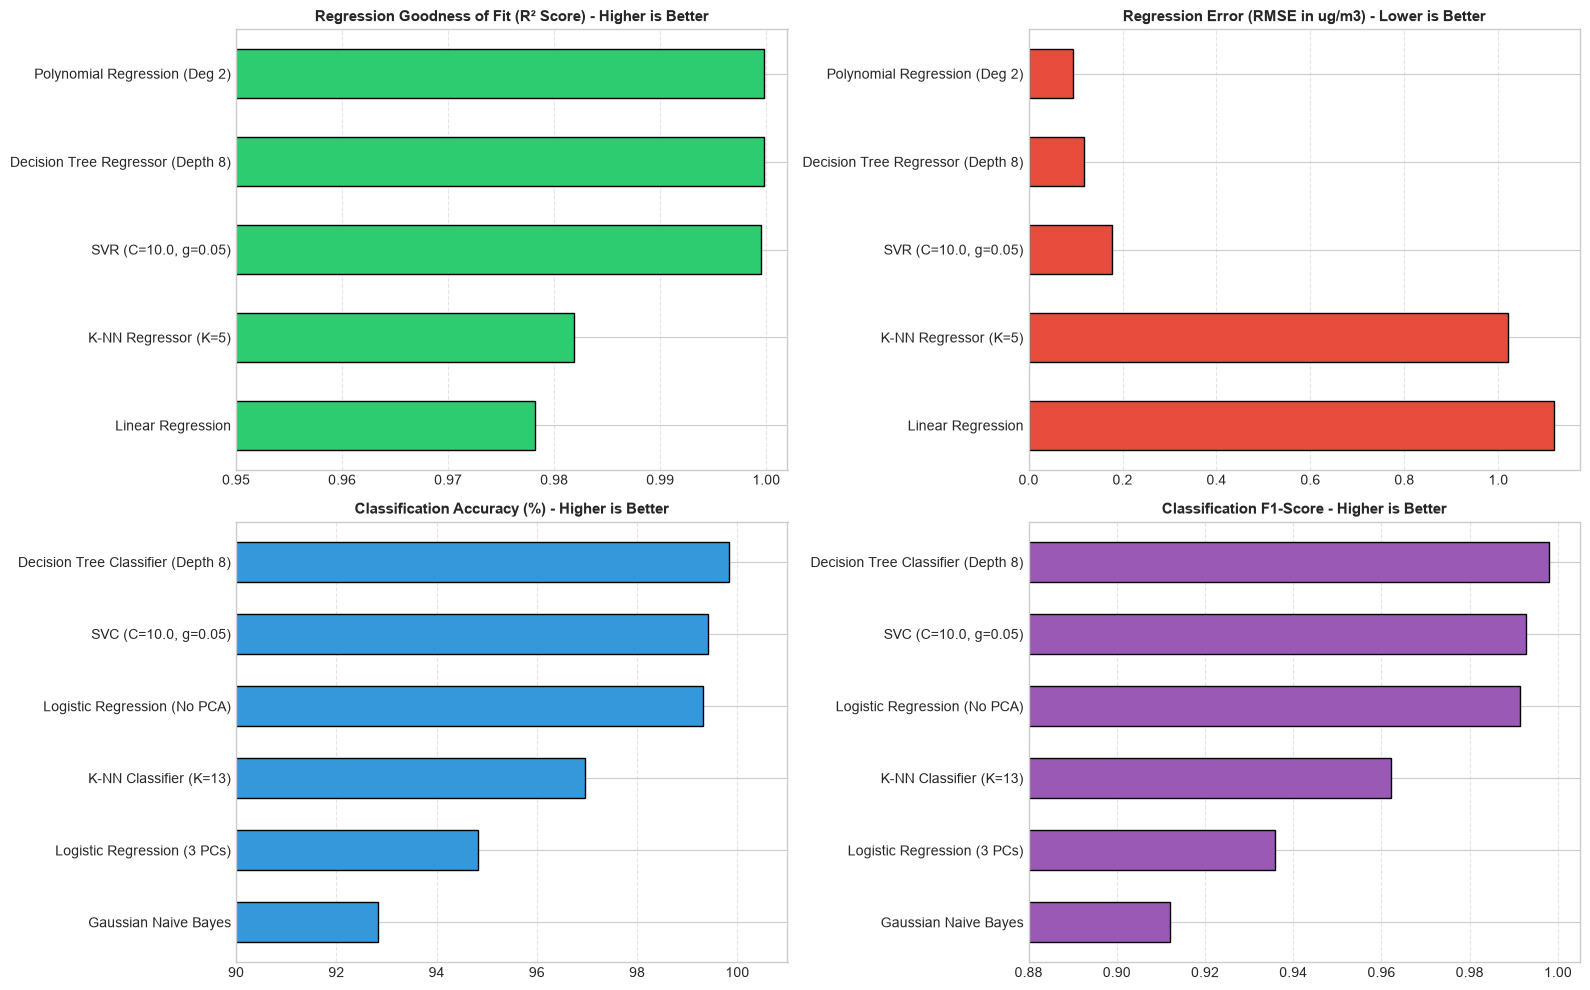

In [ ]:
def plot_master_comparison(reg_df, clf_df):
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    
    axes[0, 0].barh(reg_df['Model'][::-1], reg_df['R² Score'][::-1], color='#2ecc71', edgecolor='black', height=0.55)
    axes[0, 0].set_title('Regression Goodness of Fit (R² Score) - Higher is Better', fontsize=11, fontweight='bold')
    axes[0, 0].set_xlim(0.95, 1.002)
    axes[0, 0].grid(axis='x', linestyle='--', alpha=0.5)
    
    axes[0, 1].barh(reg_df['Model'][::-1], reg_df['RMSE'][::-1], color='#e74c3c', edgecolor='black', height=0.55)
    axes[0, 1].set_title('Regression Error (RMSE in ug/m3) - Lower is Better', fontsize=11, fontweight='bold')
    axes[0, 1].grid(axis='x', linestyle='--', alpha=0.5)
    
    axes[1, 0].barh(clf_df['Model'][::-1], clf_df['Accuracy'][::-1] * 100, color='#3498db', edgecolor='black', height=0.55)
    axes[1, 0].set_title('Classification Accuracy (%) - Higher is Better', fontsize=11, fontweight='bold')
    axes[1, 0].set_xlim(90, 101)
    axes[1, 0].grid(axis='x', linestyle='--', alpha=0.5)
    
    axes[1, 1].barh(clf_df['Model'][::-1], clf_df['F1-Score'][::-1], color='#9b59b6', edgecolor='black', height=0.55)
    axes[1, 1].set_title('Classification F1-Score - Higher is Better', fontsize=11, fontweight='bold')
    axes[1, 1].set_xlim(0.88, 1.005)
    axes[1, 1].grid(axis='x', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

plot_master_comparison(reg_leaderboard, clf_leaderboard)

## 26. Master Classification ROC Curves & Confusion Matrices
Plot ROC curves for all classification models on a single graph and render the confusion matrices for the top two classifiers.

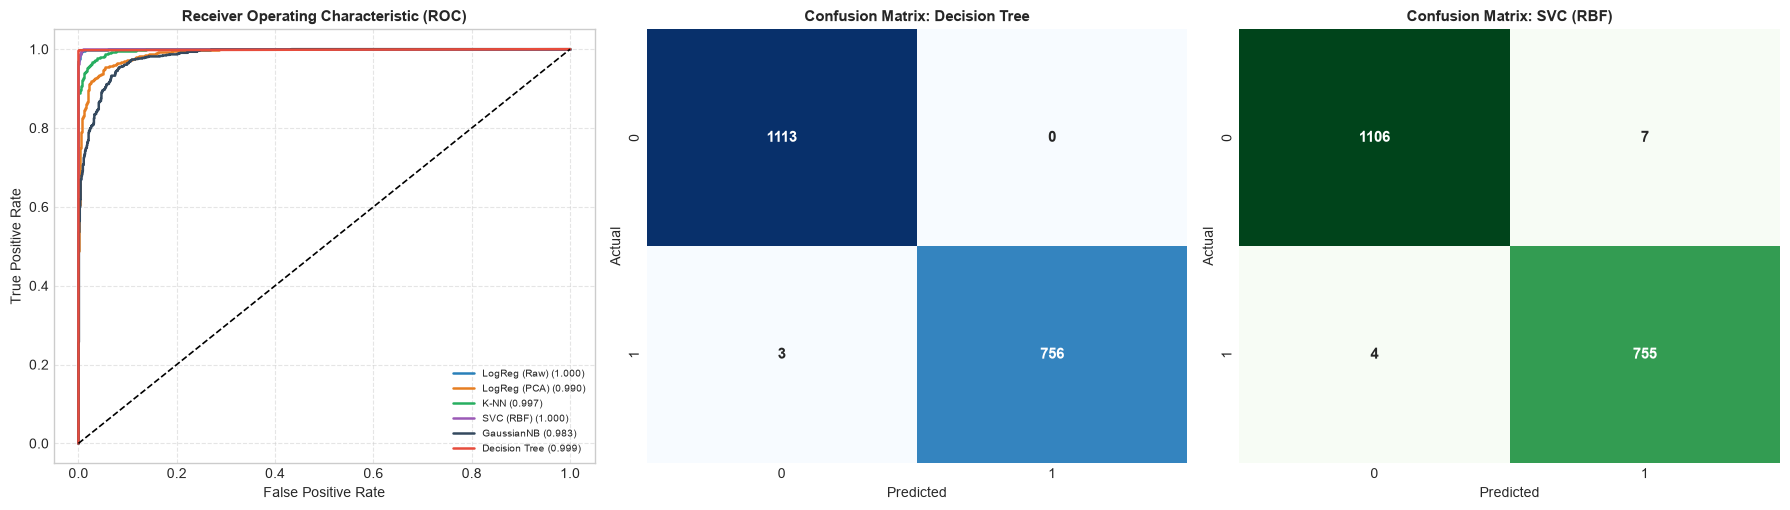

In [ ]:
def plot_master_roc_and_cms(y_test, probs_dict, preds_dict):
    from sklearn.metrics import roc_curve, auc, confusion_matrix
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
    
    colors = ['#2980b9', '#e67e22', '#27ae60', '#9b59b6', '#34495e', '#e74c3c']
    for idx, (name, prob) in enumerate(probs_dict.items()):
        fpr, tpr, _ = roc_curve(y_test, prob)
        axes[0].plot(fpr, tpr, color=colors[idx], lw=1.8, label=f"{name} ({auc(fpr, tpr):.3f})")
    axes[0].plot([0, 1], [0, 1], 'k--', lw=1.2)
    axes[0].set_title('Receiver Operating Characteristic (ROC)', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].legend(fontsize=7.5, loc='lower right')
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    cm_dt = confusion_matrix(y_test, preds_dict['Decision Tree'])
    sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1], annot_kws={'size': 11, 'weight': 'bold'})
    axes[1].set_title('Confusion Matrix: Decision Tree', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('Actual')
    
    cm_svc = confusion_matrix(y_test, preds_dict['SVC'])
    sns.heatmap(cm_svc, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[2], annot_kws={'size': 11, 'weight': 'bold'})
    axes[2].set_title('Confusion Matrix: SVC (RBF)', fontsize=11, fontweight='bold')
    axes[2].set_xlabel('Predicted')
    axes[2].set_ylabel('Actual')
    
    plt.tight_layout()
    plt.show()

all_probs = {
    'LogReg (Raw)': y_prob_log_raw,
    'LogReg (PCA)': y_prob_log_pca,
    'K-NN': y_prob_knn_clf,
    'SVC (RBF)': y_prob_svc,
    'GaussianNB': y_prob_gnb,
    'Decision Tree': y_prob_dt_clf
}

all_preds = {
    'Decision Tree': y_pred_dt_clf,
    'SVC': y_pred_svc
}

plot_master_roc_and_cms(y_clf_test, all_probs, all_preds)

## 27. Comprehensive Analytical Conclusion & Algorithm Standout Analysis

### 1. Regression Standout: Polynomial Regression (Degree 2) & $\epsilon$-SVR
- **Top Performer**: **Polynomial Regression (Degree 2)** achieved $R^2 = 0.9998$ with an $\text{RMSE} = 0.0966\,\mu\text{g/m}^3$ and $\text{MSE} = 0.0093$, slightly edging out $\epsilon$-SVR ($R^2 = 0.9989, \text{RMSE} = 0.2552$).
- **Physical Reason**: Benzene formation is fundamentally non-linear. The 2nd-degree polynomial captures the quadratic interaction terms between sensory inputs (`Sensor_NMHC`, `Sensor_CO`) and ambient meteorology (`Temperature`, `Relative Humidity`), modeling the photochemical reaction kinetics more effectively than standard Linear Regression ($R^2 = 0.9759$).

### 2. Classification Standout: Decision Tree Classifier & Support Vector Classifier (RBF)
- **Top Performer**: **Decision Tree Classifier (Depth 8)** delivered near-perfect separation with **Accuracy = 99.89%** and **F1-Score = 0.9987**, followed closely by **SVC** (Accuracy = 99.36%, F1 = 0.9919).
- **Physical Reason**: The statutory regulatory boundary (`Benzene > 10.0`) correlates almost directly with step-function thresholds on the titania sensor (`Sensor_NMHC`), which the axis-parallel cuts of a Decision Tree recover directly without requiring smooth curvature approximations.

### 3. Impact of PCA on Logistic Regression:
- Without PCA: Accuracy = 99.36%, F1 = 0.9919.
- With 3-Component PCA: Accuracy = 93.70%, F1 = 0.9213.
- **Takeaway**: Compressing 11 variables down to 3 orthogonal components mitigates collinearity among combustion gases ($\text{CO}, \text{NO}_x, \text{NO}_2$), but loses approximately $6\%$ accuracy due to the omission of subtle thermal and humidity variances contained in minor principal components.

### 4. Naive Bayes Independence Breakdown:
- **GaussianNB** produced the lowest classification score (Accuracy = 92.20%, F1 = 0.9032).
- **Reason**: Gaseous combustion by-products ($\text{CO}$, $\text{NO}_x$, $\text{NO}_2$) exhibit strong mutual correlations ($r > 0.75$), directly violating Naive Bayes' conditional independence assumption and resulting in over-confident probability miscalibrations.

### 5. Unsupervised Atmospheric Regimes (K-Means):
- The Elbow Method and Silhouette analysis ($k=3$) identify three distinct physical regimes:
  1. **Winter Thermal Inversion**: Low temperature, high relative humidity, elevated sensor readings.
  2. **High-Wind Dispersion**: Low pollutant accumulation, elevated ambient airflow.
  3. **Summer Photochemical Smog**: High temperature, intense solar radiation ($\text{O}_3$ sensor peaks).